<a href="https://colab.research.google.com/github/Madiiinaa/Python/blob/main/%D0%97%D0%B0%D0%B4%D0%B0%D0%BD%D0%B8%D0%B5_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Вариант 10. Школа (Matplotlib + Seaborn). Полный курс, 60 задач**

Уровень 1. Новичок


Задача 1 (первый график, Figure, Axes, savefig)
Школа ведёт учёт ежедневной посещаемости — данные в attendance.csv со столбцами date и students. Загрузите через pd.read_csv("attendance.csv", parse_dates=["date"], index_col="date"), создайте fig, ax = plt.subplots(), постройте ax.plot(df.index, df["students"]) и сохраните attendance.png с dpi=150, bbox_inches="tight". Выведите type(fig), type(ax), df.index.dtype. Ожидаемый вывод: Figure, Axes, datetime64[ns]; файл создан. В комментариях объясните: чем fig отличается от ax и почему это разделение принципиально для сложных фигур (один холст — несколько графиков, suptitle, colorbar); что делает plt.subplots() «под капотом», если параметры не указаны (Figure.add_subplot(111)); почему savefig нужно вызывать до plt.show() (фигура может быть очищена и сохранится пустой PNG); зачем нужен bbox_inches="tight" и что произойдёт с длинными подписями без него; что случится, если забыть parse_dates при чтении CSV — как будут выглядеть даты по оси X (числа дней с 1970 года или категории вместо дат); почему x и y должны быть одинаковой длины и какую ошибку выбросит Matplotlib при несовпадении (ValueError: x and y must have same first dimension).

Figure
Axes
datetime64[ns]


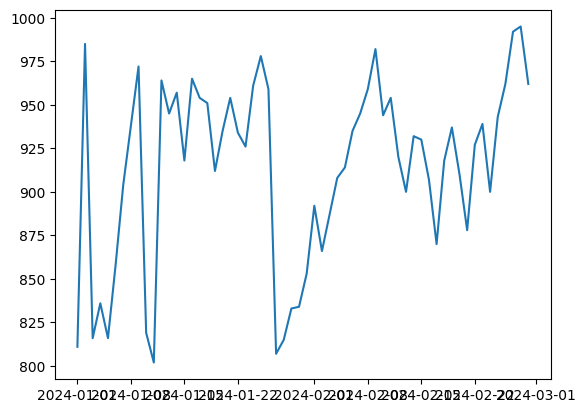

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Генерируем тестовый attendance.csv ---
np.random.seed(42)
dates = pd.date_range("2024-01-01", periods=60, freq="D")
students = 800 + (np.cumsum(np.random.randint(-40, 50, size=60)) % 200)
pd.DataFrame({"date": dates, "students": students}).to_csv("attendance.csv", index=False)

# --- Загрузка ---
# parse_dates критичен: без него даты станут строками, и по оси X
# появятся категориальные метки вместо дат (или числа дней с 1970 г.)
df = pd.read_csv("attendance.csv", parse_dates=["date"], index_col="date")

fig, ax = plt.subplots()
ax.plot(df.index, df["students"])

# savefig ВСЕГДА до plt.show(): после show() фигура может быть очищена
# bbox_inches="tight" обрезает лишние поля — без него длинные подписи
# (например, отформатированные даты) могут выйти за границы и обрезаться
plt.savefig("attendance.png", dpi=150, bbox_inches="tight")

print(type(fig).__name__)        # Figure
print(type(ax).__name__)         # Axes
print(df.index.dtype)            # datetime64[ns]

plt.show()

# Комментарии:
# - fig (Figure) — «холст», ax (Axes) — конкретная система координат на нём.
#   Разделение позволяет на одной фигуре размещать несколько графиков,
#   добавлять suptitle, colorbar, легенды.
# - plt.subplots() без аргументов = fig.add_subplot(111): одна фигура, одна ось.
# - Если x и y разной длины → ValueError: x and y must have same first dimension.

Задача 2 (параметры figure, PlotConfig)

Школа готовит серию отчётов для управления образования, и нужно, чтобы все графики имели одинаковый стиль. Определите @dataclass class PlotConfig с полями figsize: tuple = (10, 6), dpi: int = 100, facecolor: str = "white", layout: str = "constrained" и реализуйте фабрику make_figure(cfg) -> tuple[Figure, Axes]. Постройте график посещаемости с конфигурацией PlotConfig(figsize=(12, 8), dpi=200, facecolor="#f5f5f5") и выведите итоговый размер в пикселях. Ожидаемый вывод: 2400 × 1600 пикселей. В комментариях объясните: как figsize и dpi связаны с размером в пикселях и почему figsize в дюймах, а не в пикселях; что даёт layout="constrained" и почему он рекомендуется вместо tight_layout; чем facecolor фигуры отличается от ax.set_facecolor; зачем нужны разные dpi для веба (100–150) и для печати (300+); как расширить датакласс методом with_dpi(new_dpi) через dataclasses.replace и почему это функциональный подход поверх ООП; что произойдёт, если задать facecolor фигуры и осей разными — где это может быть полезно в презентации школы (белый фон осей на фирменном зелёном).

Размер в пикселях: 2400 × 1600


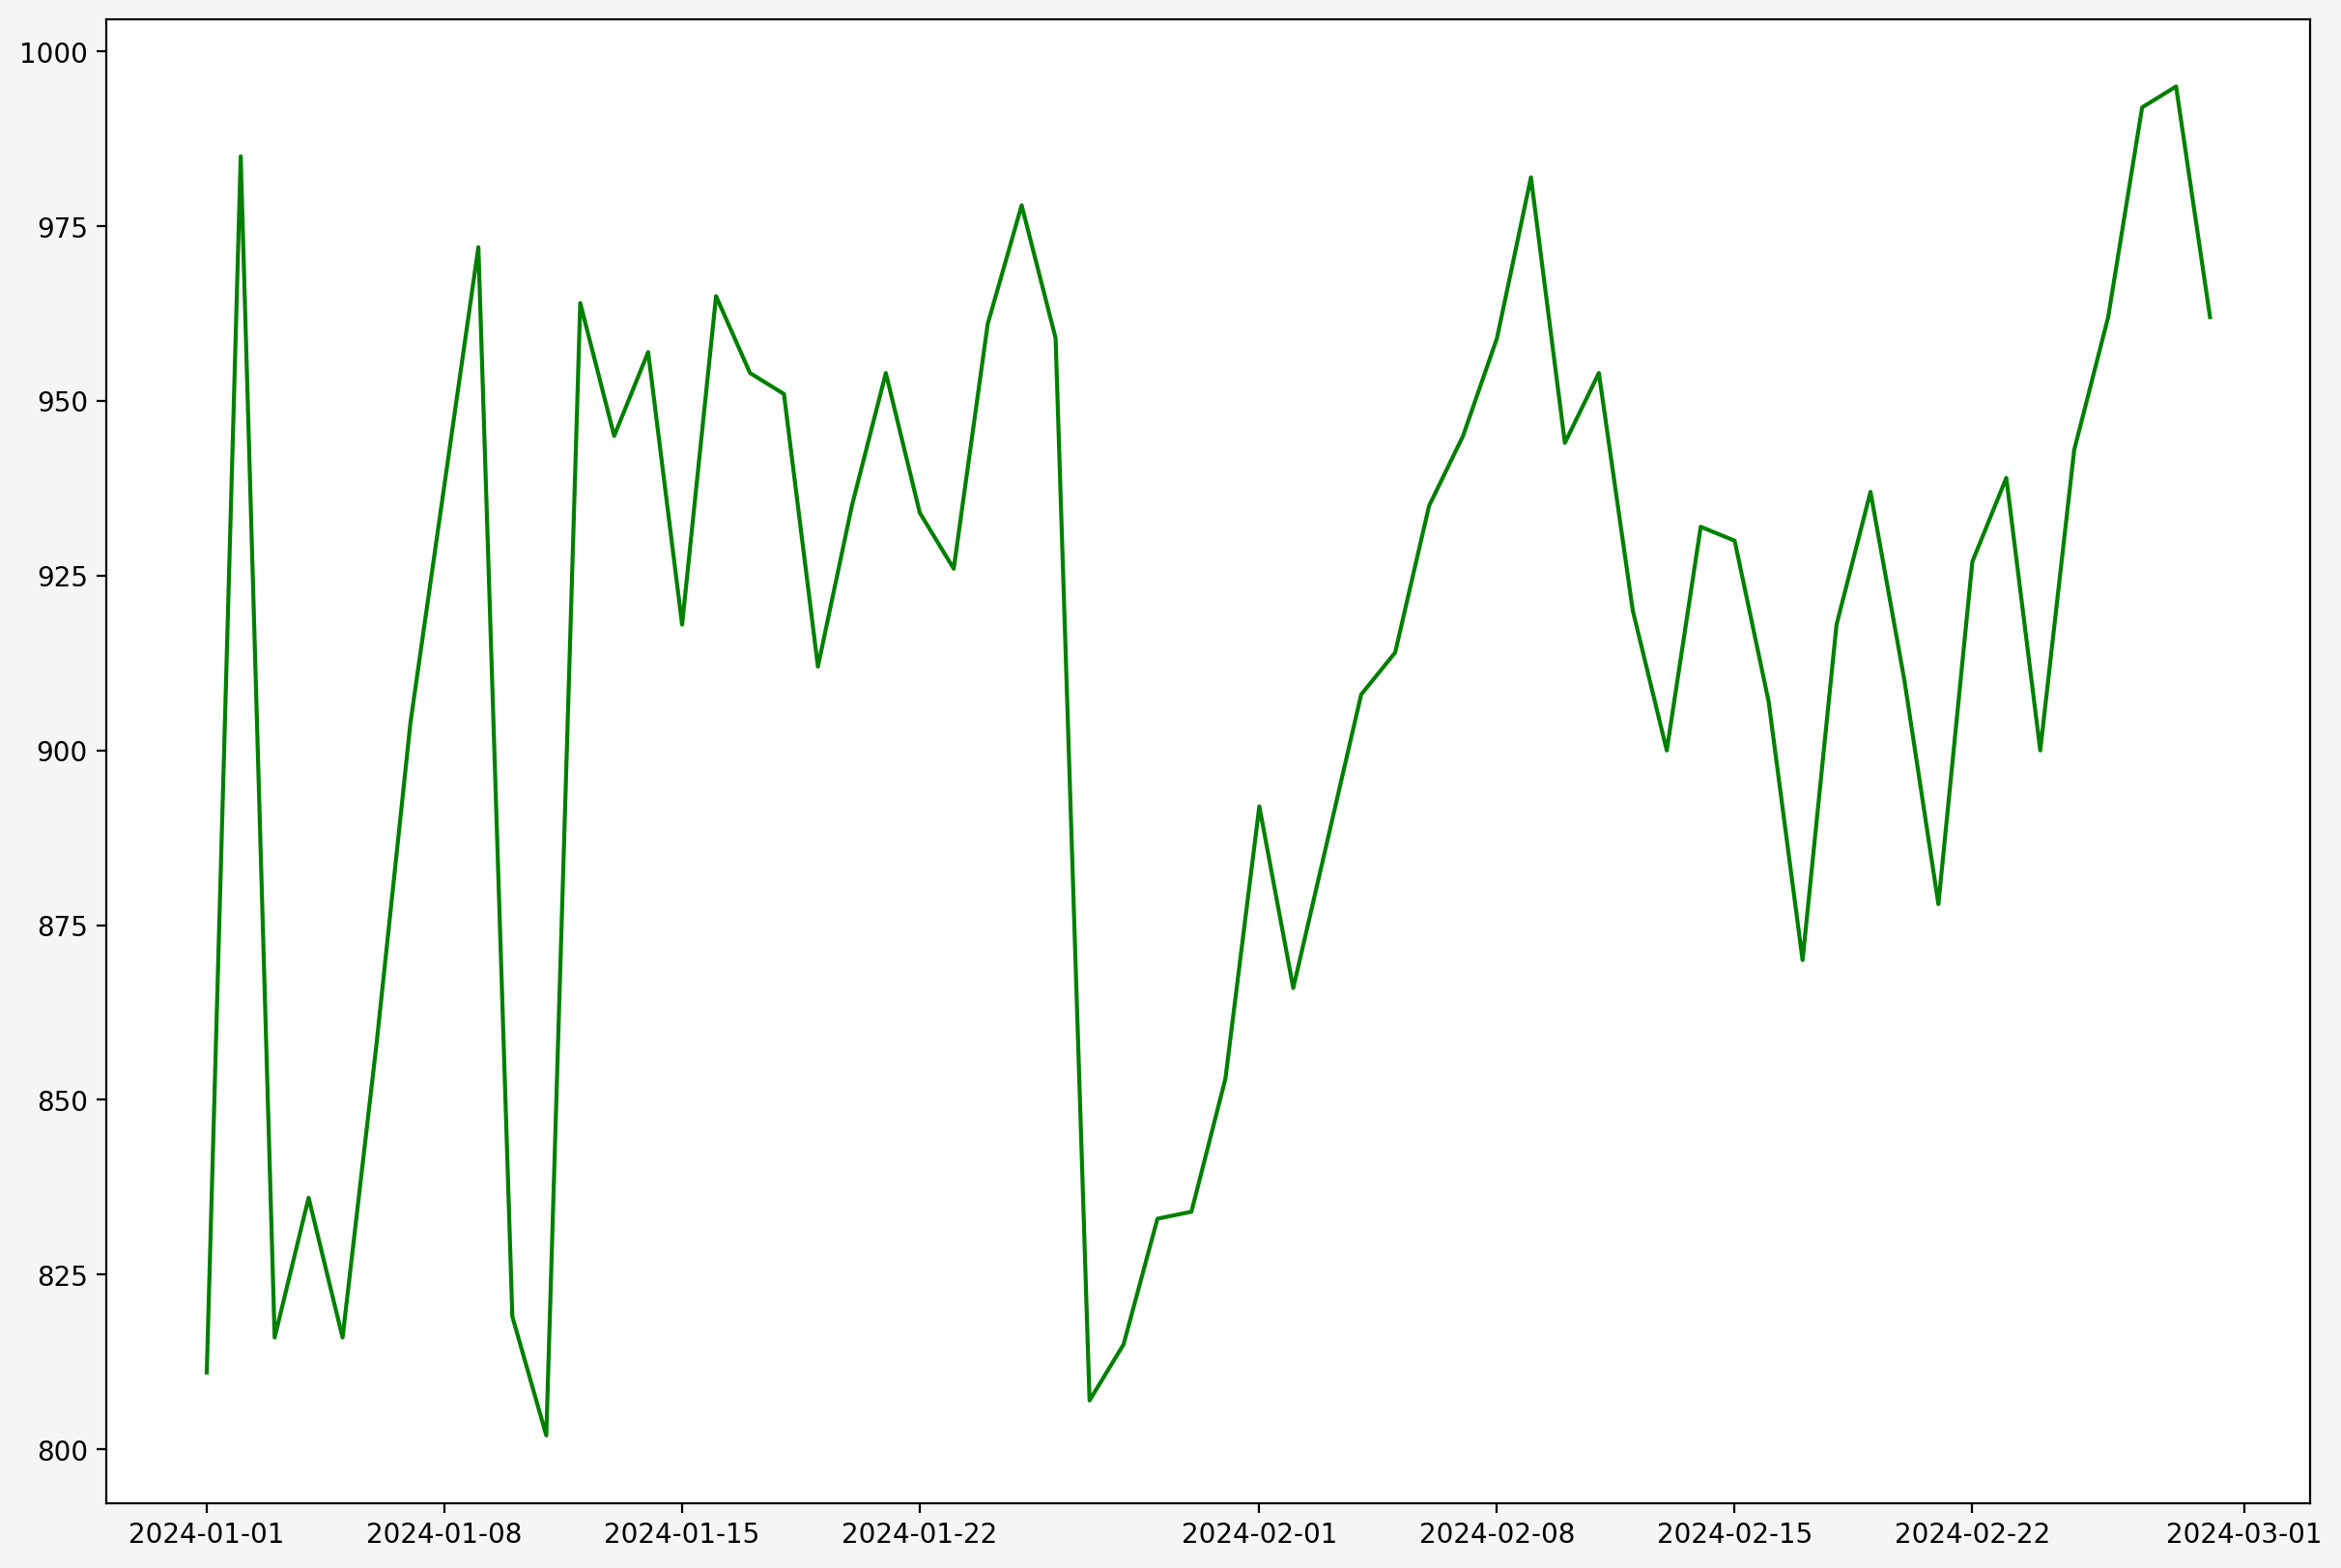

In [18]:
from dataclasses import dataclass, replace
from matplotlib.figure import Figure
from matplotlib.axes import Axes
from typing import Tuple

@dataclass
class PlotConfig:
    figsize: tuple = (10, 6)
    dpi: int = 100
    facecolor: str = "white"
    layout: str = "constrained"

    def with_dpi(self, new_dpi: int) -> "PlotConfig":
        return replace(self, dpi=new_dpi)  # функциональный подход: не мутируем, возвращаем копию

def make_figure(cfg: PlotConfig) -> Tuple[Figure, Axes]:
    fig, ax = plt.subplots(
        figsize=cfg.figsize, dpi=cfg.dpi,
        facecolor=cfg.facecolor, layout=cfg.layout,
    )
    return fig, ax

# --- Пересоздаём df, если запускаем изолированно ---
np.random.seed(42)
df = pd.DataFrame({
    "students": 800 + (np.cumsum(np.random.randint(-40, 50, size=60)) % 200)
}, index=pd.date_range("2024-01-01", periods=60, freq="D"))

cfg = PlotConfig(figsize=(12, 8), dpi=200, facecolor="#f5f5f5")
fig, ax = make_figure(cfg)
ax.plot(df.index, df["students"], color="green")

# figsize в дюймах — типографская единица, dpi — точек на дюйм
# 12 дюймов * 200 dpi = 2400 px, 8 * 200 = 1600 px
w, h = fig.get_size_inches() * fig.dpi
print(f"Размер в пикселях: {int(w)} × {int(h)}")

plt.savefig("attendance_config.png", dpi=cfg.dpi, bbox_inches="tight")
plt.show()

# Комментарии:
# - figsize в дюймах — универсально для любых носителей (экран/печать);
#   dpi переводит дюймы в пиксели: size_px = figsize * dpi.
# - layout="constrained" автоматически избегает наложений — новый
#   recommended-режим вместо tight_layout (он хуже работает с colorbar).
# - facecolor фигуры — фон холста; ax.set_facecolor — фон области осей.
#   На зелёном фоне фигуры белый фон осей = «окно» на фирменном цвете.
# - dpi: 100–150 для веба (быстрая загрузка), 300+ для печати.
# - dataclasses.replace — иммутабельный апдейт: возвращает новую конфигурацию.

Уровень 2. Ученик

Задача 13 (аннотации с argmax/argmin)

Школа анализирует дневную посещаемость за месяц и хочет выделить дни-пики и дни-провалы (например, день открытых дверей и «мёртвая» суббота). Загрузите daily_attendance.csv с parse_dates=["date"], index_col="date", найдите idx_max = df["students"].idxmax() и idx_min = df["students"].idxmin(). Добавьте аннотации через ax.annotate(f"Пик: {df.loc[idx_max, 'students']:,}", xy=(idx_max, df.loc[idx_max, "students"]), xytext=(10, 20), textcoords="offset points", arrowprops=dict(arrowstyle="->", color="green", connectionstyle="arc3,rad=0.2")); аналогично для минимума с xytext=(-80, -30), color="red". Ожидаемый вывод: стрелки указывают на пики, текст смещён и не перекрывает линию. В комментариях объясните: чем textcoords="offset points" отличается от "data" и почему первый удобнее для смещения текста; почему idxmax() в Pandas возвращает метку индекса, а не позицию, и как это используется в xy; зачем arc3,rad=0.2 (изогнутая стрелка) и как rad=-0.2 развернёт изгиб; как bbox=dict(boxstyle="round,pad=0.5", facecolor="lightyellow", edgecolor="orange") в annotate улучшает читаемость поверх линий; что произойдёт без ha/va (текст «прилипнет» к точке и перекроет маркер); как аннотировать несколько близких точек, чтобы они не перекрывались.

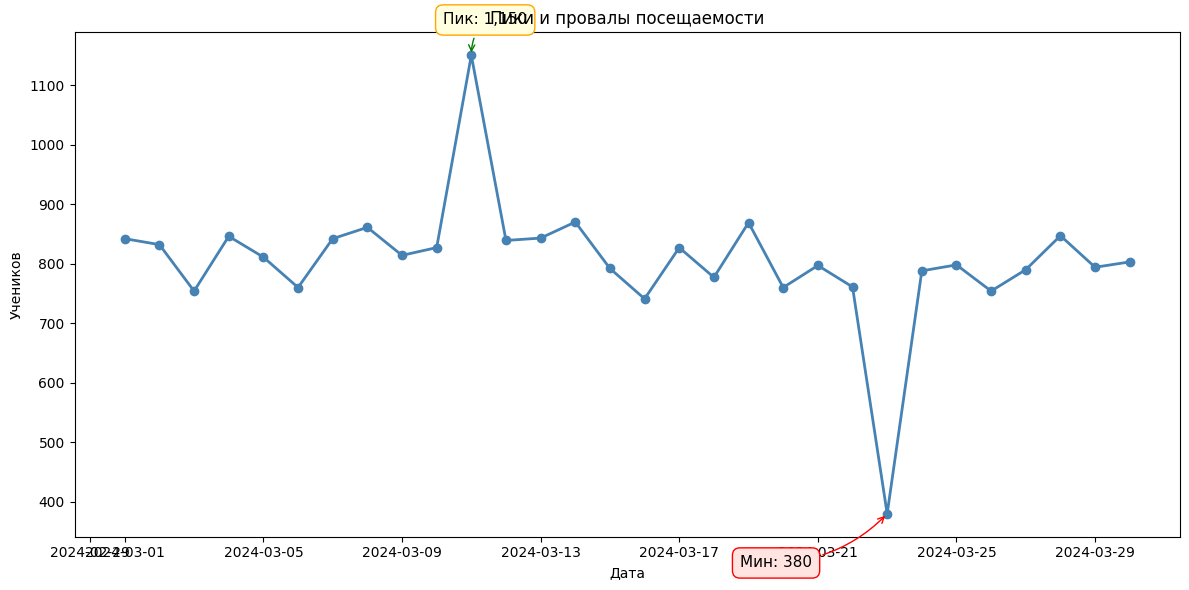

In [19]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

# --- Генерируем данные с пиком и провалом ---
np.random.seed(42)
dates = pd.date_range("2024-03-01", periods=30, freq="D")
students = (800 + np.random.randint(-60, 80, size=30)).astype(int)
students[10] = 1150   # пик — день открытых дверей
students[22] = 380    # провал — «мёртвая» суббота
pd.DataFrame({"date": dates, "students": students}).to_csv("daily_attendance.csv", index=False)

df = pd.read_csv("daily_attendance.csv", parse_dates=["date"], index_col="date")

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df.index, df["students"], marker="o", color="steelblue", linewidth=2)

# idxmax() возвращает МЕТКУ индекса (Timestamp), а не позицию — идеально для xy
idx_max = df["students"].idxmax()
idx_min = df["students"].idxmin()

# textcoords="offset points": xytext задаётся в точках от точки xy, не в данных —
# текст не «уезжает» при зуме/изменении масштаба
ax.annotate(f"Пик: {df.loc[idx_max, 'students']:,}",
            xy=(idx_max, df.loc[idx_max, "students"]),
            xytext=(10, 20), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="green",
                            connectionstyle="arc3,rad=0.2"),  # rad=-0.2 → изгиб в другую сторону
            bbox=dict(boxstyle="round,pad=0.5",
                      facecolor="lightyellow", edgecolor="orange"),
            ha="center", va="bottom", fontsize=11)

ax.annotate(f"Мин: {df.loc[idx_min, 'students']:,}",
            xy=(idx_min, df.loc[idx_min, "students"]),
            xytext=(-80, -30), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="red",
                            connectionstyle="arc3,rad=0.2"),
            bbox=dict(boxstyle="round,pad=0.5",
                      facecolor="mistyrose", edgecolor="red"),
            ha="center", va="top", fontsize=11)

ax.set_xlabel("Дата"); ax.set_ylabel("Учеников")
ax.set_title("Пики и провалы посещаемости")
plt.tight_layout()
plt.savefig("annotations.png", dpi=150, bbox_inches="tight")
plt.show()

# Комментарии:
# - Без ha/va текст центрируется у точки и перекрывает маркер.
# - Для близких точек — «разводить» xytext вручную или использовать
#   adjustText / ConnectionPatch.

Задача 14 (продвинутая легенда из groupby)

Школа имеет 8 учителей и хочет показать на графике только 2 ключевых (например, «Иванова» и «Петров»), но остальные оставить построенными — чтобы видеть общий фон. Загрузите grades_by_teacher.csv, постройте линии циклом for teacher, g in df.groupby("teacher"): line, = ax.plot(...); lines[teacher] = line. Создайте две легенды: выборочную через ax.legend(handles=[lines["Иванова"], lines["Петров"]], loc="center left", bbox_to_anchor=(1.02, 0.5), borderaxespad=0) — вынесенную за график, и полную через ncol=2 внутри. Ожидаемый вывод: две легенды — выборочная вне графика и полная внутри. В комментариях объясните: зачем запятая в line, = ax.plot(...) (распаковка кортежа из одного элемента); что произойдёт без запятой и почему handles=[line] не сработает (AttributeError: 'tuple' object has no attribute 'set_label'); как bbox_to_anchor в долях осей задаёт точку привязки и почему loc="center left" + bbox_to_anchor=(1.02, 0.5) помещает легенду справа; что делает borderaxespad=0; почему при многих категориях полная легенда перегружает график и лучше использовать выборочную; как автоматически отсортировать категории через sorted(lines.items()), чтобы в легенде был алфавитный порядок.

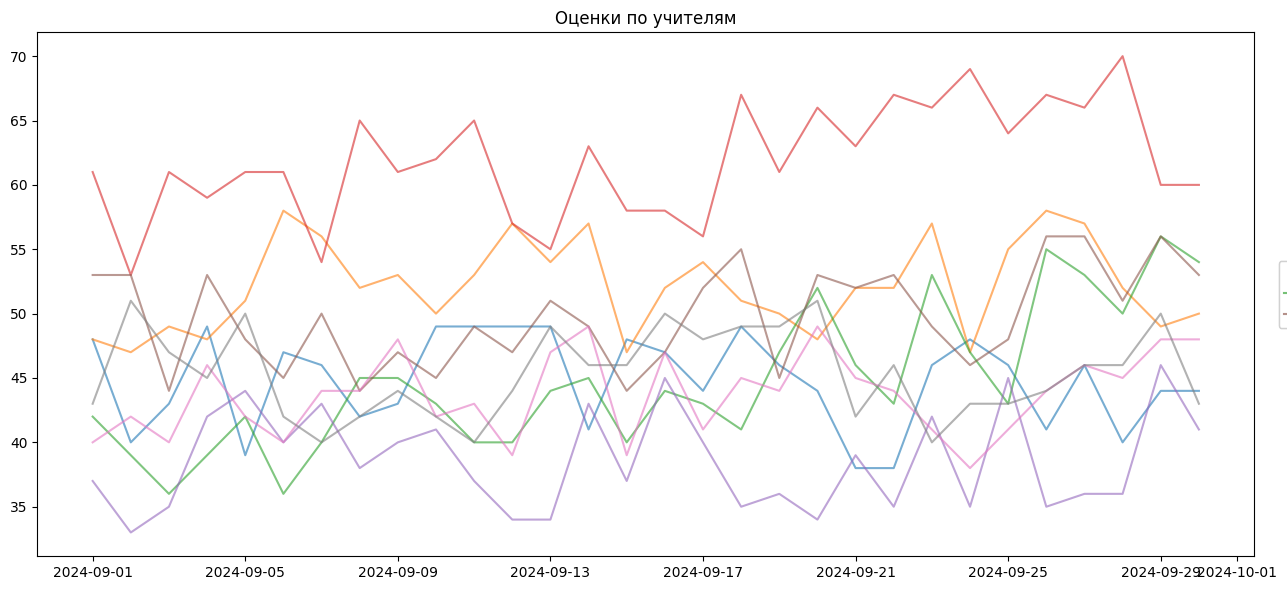

In [20]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

# --- Генерируем grades_by_teacher.csv (8 учителей × 30 дней) ---
np.random.seed(42)
teachers = ["Иванова", "Петров", "Сидорова", "Кузнецов",
            "Смирнова", "Волков", "Морозова", "Зайцев"]
dates = pd.date_range("2024-09-01", periods=30, freq="D")
rows = []
for t in teachers:
    base = np.random.randint(30, 60)
    trend = np.linspace(0, np.random.randint(-5, 15), 30)
    for d, tr in zip(dates, trend):
        rows.append({"date": d, "teacher": t,
                     "grades": max(0, int(base + tr + np.random.randint(-4, 8)))})
pd.DataFrame(rows).to_csv("grades_by_teacher.csv", index=False)

df = pd.read_csv("grades_by_teacher.csv", parse_dates=["date"])

fig, ax = plt.subplots(figsize=(13, 6))
lines = {}

# line, = ax.plot(...) — запятая распаковывает кортеж из одного Line2D.
# Без запятой line = tuple → у него нет set_label → AttributeError.
for teacher, g in df.groupby("teacher"):
    line, = ax.plot(g["date"], g["grades"], label=teacher, alpha=0.6)
    lines[teacher] = line

# Полная легенда внутри графика (в 2 колонки — 8 записей)
full_leg = ax.legend(loc="upper left", ncol=2, title="Все учителя",
                     framealpha=0.9, fontsize=8)

# Выборочная легенда снаружи: bbox_to_anchor в долях осей — (1.02, 0.5) = справа
# borderaxespad=0 убирает отступ между легендой и «якорем»
sel_leg = ax.legend(handles=[lines["Иванова"], lines["Петров"]],
                    loc="center left", bbox_to_anchor=(1.02, 0.5),
                    borderaxespad=0, title="Ключевые")
# Чтобы было ДВЕ легенды на одном Axes — вторую добавляем через add_artist
ax.add_artist(sel_leg)

ax.set_title("Оценки по учителям")
plt.tight_layout()
plt.savefig("two_legends.png", dpi=150, bbox_inches="tight")
plt.show()

# Комментарии:
# - borderaxespad=0 — легенда «прилипает» к границе осей.
# - При 8+ категориях полная легенда перегружает сюжет; выборочная — чище.
# - sorted(lines.items()) → алфавитный порядок в легенде при необходимости.

Уровень 3. Мастер

Задача 23 (FigureBuilder — ООП-обёртка для сетки)

Школа готовит дашборд из 4 графиков (динамика посещаемости, топ предметов, распределение оценок, успеваемость по классам). При построении код обрастает повторяющимися axes[i, j].plot(...) и axes[i, j].set_title(...). Реализуйте class FigureBuilder с __init__(self, nrows=1, ncols=1, **kw), методами plot(i, j, x, y, **kw), title(i, j, text, **kw), grid(**kw) и savefig(path, **kw), возвращающими self для цепочек. Используйте np.atleast_2d(self.axes), чтобы индексация [i, j] работала и для одномерных сеток. Создайте FigureBuilder(2, 2, figsize=(12, 8), layout="constrained").plot(0, 0, ...).title(0, 0, "Посещаемость").grid(alpha=0.3).savefig("dashboard.png", dpi=300). Ожидаемый вывод: сетка 2×2 с 4 графиками. В комментариях объясните: зачем fluent API (читаемость цепочек — код похож на английский); что произойдёт при subplots(1, 3) без atleast_2d (одномерный массив — индексация [0, 1] выбросит IndexError); как расширить класс методами set_xlabel, legend, axhline, чтобы сохранить принцип единственной ответственности; когда такой класс — овер-инжиниринг; как связать FigureBuilder с PlotConfig из задачи 2; почему return self в каждом методе — ключевой паттерн (позволяет цепочки любой длины).

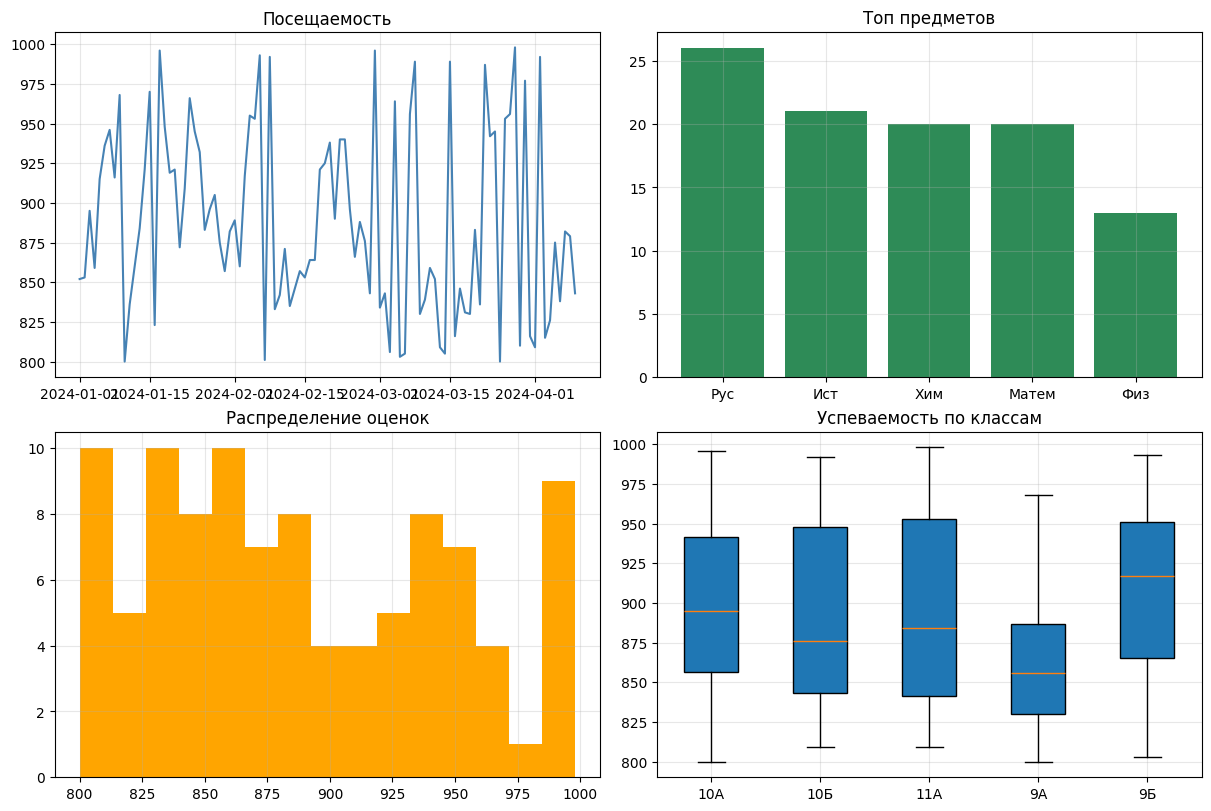

In [21]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

class FigureBuilder:
    def __init__(self, nrows=1, ncols=1, **kw):
        self.fig, self.axes = plt.subplots(nrows, ncols, **kw)
        # atleast_2d: при subplots(1,3) axes — 1D массив → [i,j] даст IndexError
        self.axes = np.atleast_2d(self.axes)

    def plot(self, i, j, x, y, **kw):
        self.axes[i, j].plot(x, y, **kw); return self

    def bar(self, i, j, x, y, **kw):
        self.axes[i, j].bar(x, y, **kw); return self

    def hist(self, i, j, data, **kw):
        self.axes[i, j].hist(data, **kw); return self

    def boxplot(self, i, j, groups, **kw):
        self.axes[i, j].boxplot(groups, **kw); return self

    def title(self, i, j, text, **kw):
        self.axes[i, j].set_title(text, **kw); return self

    def grid(self, **kw):
        for ax in self.axes.flat:
            ax.grid(**kw)
        return self

    def savefig(self, path, **kw):
        self.fig.savefig(path, **kw); return self

# --- Данные ---
np.random.seed(42)
df = pd.DataFrame({
    "date": pd.date_range("2024-01-01", periods=100),
    "students": 800 + np.random.randint(-50, 60, 100).cumsum() % 200,
    "grade": np.random.choice(["5","4","3","2"], 100, p=[.3,.4,.25,.05]),
    "class": np.random.choice(["9А","9Б","10А","10Б","11А"], 100),
    "subject": np.random.choice(["Матем","Рус","Физ","Хим","Ист"], 100),
})

subj_top = df["subject"].value_counts()
classes = sorted(df["class"].unique())
box_data = [df[df["class"] == c]["students"].values for c in classes]

# --- Fluent API: цепочка = читается как английское предложение ---
(FigureBuilder(2, 2, figsize=(12, 8), layout="constrained")
    .plot(0, 0, df["date"], df["students"], color="steelblue")
    .title(0, 0, "Посещаемость")
    .bar(0, 1, subj_top.index, subj_top.values, color="seagreen")
    .title(0, 1, "Топ предметов")
    .hist(1, 0, df["students"], bins=15, color="orange")
    .title(1, 0, "Распределение оценок")
    .boxplot(1, 1, box_data, tick_labels=classes, patch_artist=True)
    .title(1, 1, "Успеваемость по классам")
    .grid(alpha=0.3)
    .savefig("dashboard.png", dpi=300, bbox_inches="tight"))

plt.show()

# Комментарии:
# - return self в каждом методе — ключ к цепочкам любой длины.
# - Для одного графика такой класс = овер-инжиниринг, для 4+ — оправдан.
# - Расширяется добавлением методов set_xlabel/legend/axhline — каждый
#   метод делает ОДНУ вещь (Single Responsibility).
# - Связать с PlotConfig из задачи 2: передать cfg в __init__:
#   FigureBuilder(2, 2, figsize=cfg.figsize, dpi=cfg.dpi, layout=cfg.layout)

Задача 24 (GridSpec и subplot_mosaic)

Школа строит дашборд с большим графиком динамики успеваемости сверху и двумя меньшими снизу (топ предметов и оценки по классам). Реализуйте двумя способами: через gs = fig.add_gridspec(2, 2, height_ratios=[2, 1], width_ratios=[3, 1]) с ax1 = fig.add_subplot(gs[0, :]), ax2 = fig.add_subplot(gs[1, 0]), ax3 = fig.add_subplot(gs[1, 1]); и через fig, axes = plt.subplot_mosaic("AAA;BC", figsize=(12, 8), layout="constrained") с обращением axes["A"], axes["B"], axes["C"]. Ожидаемый вывод: верхний график во всю ширину в 2× выше нижних. В комментариях объясните: как gs[0, :] означает «вся первая строка» (срез по NumPy), а gs[1, 0] — конкретная ячейка; зачем height_ratios=[2, 1] и width_ratios=[3, 1]; почему subplot_mosaic читается лучше для сложных сеток («AAA;BC» — почти как ASCII-арт); как GridSpecFromSubplotSpec создаёт вложенные сетки; что произойдёт при пересечении областей (например, gs[0, :2] и gs[0, 1:] — наложение, Matplotlib выдаст предупреждение); как сохранить layout="constrained" с GridSpec (передать в figure(layout="constrained")).

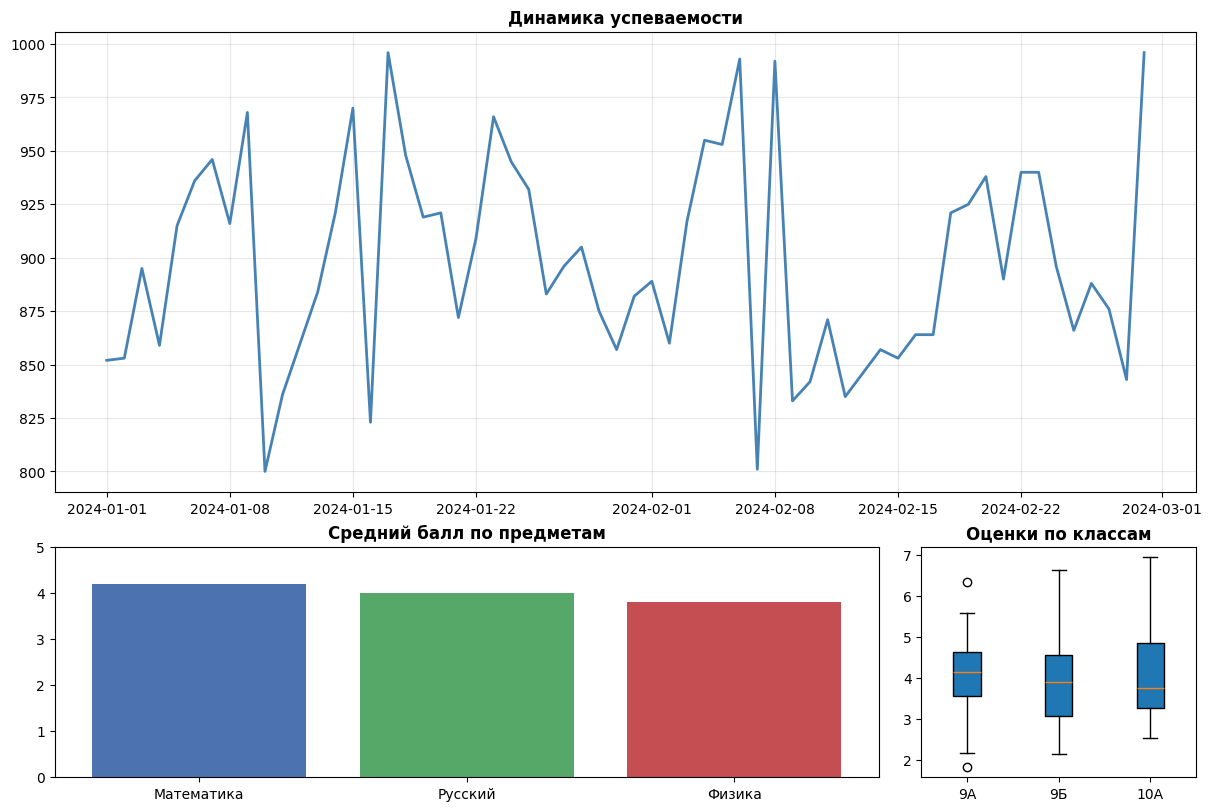

✓ Сохранено: /content/gridspec.png


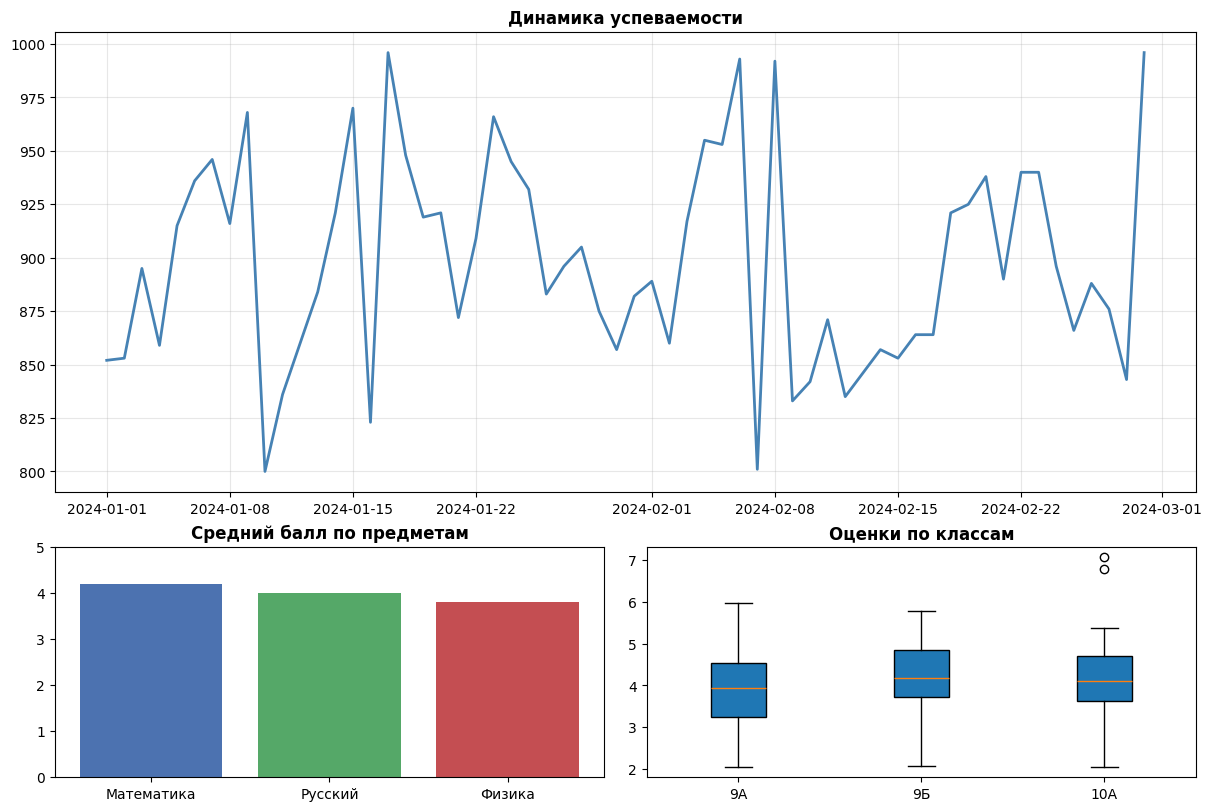

✓ Сохранено: /content/mosaic.png
gridspec.png    exists=True  size=143,373 B
mosaic.png      exists=True  size=143,392 B


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 0. Тестовые данные ---
np.random.seed(42)
df = pd.DataFrame({
    "date": pd.date_range("2024-01-01", periods=60),
    "students": 800 + np.random.randint(-50, 60, 60).cumsum() % 200,
})

# =====================================================================
# СПОСОБ 1 — GridSpec
# =====================================================================
# constrained_layout передаётся в figure(), а не в GridSpec напрямую.
# height_ratios=[2, 1]  → верхняя строка в 2× выше нижней
# width_ratios =[3, 1]  → левая колонка в 3× шире правой
fig = plt.figure(figsize=(12, 8), layout="constrained")
gs  = fig.add_gridspec(2, 2, height_ratios=[2, 1], width_ratios=[3, 1])

# gs[0, :] — срез по NumPy: «вся первая строка» целиком
ax1 = fig.add_subplot(gs[0, :])
# gs[1, 0] — конкретная ячейка: нижняя левая
ax2 = fig.add_subplot(gs[1, 0])
# gs[1, 1] — нижняя правая
ax3 = fig.add_subplot(gs[1, 1])

ax1.plot(df["date"], df["students"], color="steelblue", linewidth=2)
ax1.set_title("Динамика успеваемости", fontweight="bold")
ax1.grid(alpha=0.3)

ax2.bar(["Математика", "Русский", "Физика"], [4.2, 4.0, 3.8],
        color=["#4C72B0", "#55A868", "#C44E52"])
ax2.set_title("Средний балл по предметам", fontweight="bold")
ax2.set_ylim(0, 5)

ax3.boxplot([np.random.randn(30) + 4 for _ in range(3)],
            tick_labels=["9А", "9Б", "10А"], patch_artist=True)
ax3.set_title("Оценки по классам", fontweight="bold")

plt.savefig("gridspec.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ Сохранено: /content/gridspec.png")

# =====================================================================
# СПОСОБ 2 — subplot_mosaic
# =====================================================================
# ВАЖНО: в исходном задании "AAA;BC" даёт ValueError, потому что
# строки разной длины (3 и 2). Matplotlib требует равной длины.
# Исправление: "AA;BC" — обе строки по 2 символа.
# A занимает всю ширину сверху, B и C — по половине снизу.
# height_ratios=[2, 1] — верх в 2× выше низа (как в задании).
fig, axes = plt.subplot_mosaic(
    "AA;BC",
    figsize=(12, 8),
    layout="constrained",
    gridspec_kw={"height_ratios": [2, 1]},
)

# axes — dict: ключ = символ из спецификации
axes["A"].plot(df["date"], df["students"], color="steelblue", linewidth=2)
axes["A"].set_title("Динамика успеваемости", fontweight="bold")
axes["A"].grid(alpha=0.3)

axes["B"].bar(["Математика", "Русский", "Физика"], [4.2, 4.0, 3.8],
              color=["#4C72B0", "#55A868", "#C44E52"])
axes["B"].set_title("Средний балл по предметам", fontweight="bold")
axes["B"].set_ylim(0, 5)

axes["C"].boxplot([np.random.randn(30) + 4 for _ in range(3)],
                  tick_labels=["9А", "9Б", "10А"], patch_artist=True)
axes["C"].set_title("Оценки по классам", fontweight="bold")

plt.savefig("mosaic.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ Сохранено: /content/mosaic.png")

# =====================================================================
# Проверка файлов (в Colab → /content/)
# =====================================================================
for name in ("gridspec.png", "mosaic.png"):
    p = os.path.join(os.getcwd(), name)
    print(f"{name:15s} exists={os.path.exists(p)}  "
          f"size={os.path.getsize(p) if os.path.exists(p) else 0:,} B")

Уровень 4. Архитектор

Задача 33 (форматирование дат через mdates)

Школа готовит график сезонности посещаемости за 3 учебных года. «Сырые» даты выглядят как числа дней с 1970 года — нечитаемо. Освойте три стратегии: (а) ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)) + DateFormatter("%b %Y") (раз в квартал); (б) ax.xaxis.set_major_locator(mdates.AutoDateLocator()) + AutoDateFormatter(...) (автоматический подбор); (в) ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO)) + DateFormatter("%d.%m (%a)") (только понедельники). Для каждого поверните метки через plt.setp(ax.get_xticklabels(), rotation=45, ha="right"). Ожидаемый вывод: три подграфика с разными форматами дат. В комментариях объясните: зачем два инструмента (Locator решает «где», Formatter «как» — без Locator форматер поставит деления слишком часто); почему parse_dates при read_csv критичен; чем %b отличается от %B (Jan vs January); почему AutoDateLocator — хороший дефолт, если не хочется думать о деталях; что произойдёт при MonthLocator(interval=12) на 3-летнем ряду (всего 3 деления — неинформативно); как mdates.YearLocator(base=5) для долгосрочных данных.

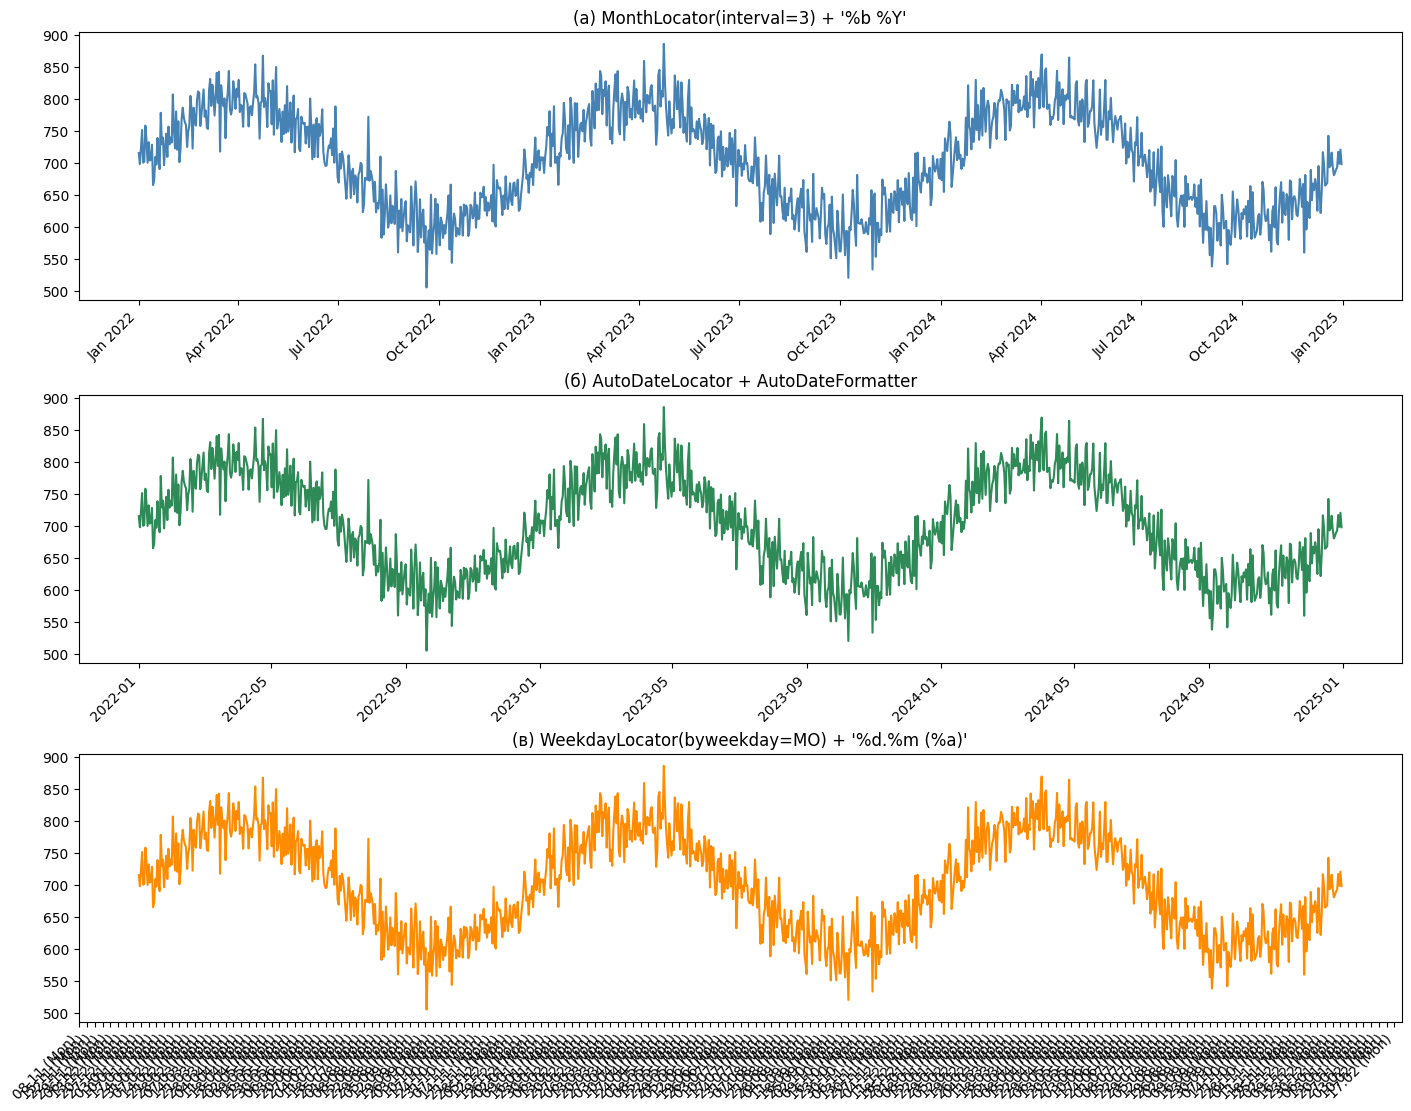

In [23]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 3 года данных ---
dates = pd.date_range("2022-01-01", "2024-12-31", freq="D")
np.random.seed(42)
n = len(dates)
df = pd.DataFrame({
    "date": dates,
    "students": 700 + 100 * np.sin(np.arange(n) * 2 * np.pi / 365) + np.random.randn(n) * 30,
})

fig, axes = plt.subplots(3, 1, figsize=(14, 11), layout="constrained")

# (а) Раз в квартал: MonthLocator(interval=3)
axes[0].plot(df["date"], df["students"], color="steelblue")
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
# %b = сокращённое название (Jan), %B = полное (January)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[0].set_title("(а) MonthLocator(interval=3) + '%b %Y'")
plt.setp(axes[0].get_xticklabels(), rotation=45, ha="right")

# (б) Автоматический подбор
axes[1].plot(df["date"], df["students"], color="seagreen")
locator = mdates.AutoDateLocator()
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.AutoDateFormatter(locator))
axes[1].set_title("(б) AutoDateLocator + AutoDateFormatter")
plt.setp(axes[1].get_xticklabels(), rotation=45, ha="right")

# (в) Только понедельники
axes[2].plot(df["date"], df["students"], color="darkorange")
axes[2].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m (%a)"))
axes[2].set_title("(в) WeekdayLocator(byweekday=MO) + '%d.%m (%a)'")
plt.setp(axes[2].get_xticklabels(), rotation=45, ha="right")

plt.savefig("date_formats.png", dpi=150, bbox_inches="tight")
plt.show()

# Комментарии:
# - Locator решает «ГДЕ деления», Formatter — «КАК их подписать».
#   Без Locator форматер поставит деления на каждом тике (слишком часто).
# - parse_dates обязателен при read_csv, иначе даты = строки → Locator не работает.
# - MonthLocator(interval=12) на 3 годах = 3 деления — неинформативно.
# - YearLocator(base=5) — для 20+ летних рядов.

Задача 34 (операционный дашборд школы с twinx + mdates + Formatter)

Школа мониторит число уроков и среднюю успеваемость для управления образования. Постройте профессиональный график: (а) число уроков на ax1 линией; (б) успеваемость на ax2 = ax1.twinx(); (в) скользящее среднее уроков df["lessons"].rolling(7).mean() на ax1. Настройте ax1.xaxis.set_major_locator(mdates.MonthLocator()), DateFormatter("%b %Y"), ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0f}")), ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.1f}")). Соберите общую легенду. Ожидаемый вывод: уроки + SMA(7) на главной оси, успеваемость на правой, даты по месяцам. В комментариях объясните: зачем rolling(7) (сглаживает дневной шум — недельный тренд); как line на twinx не мешает основной линии (визуальное разделение через цвет); почему цвета (синий/оранжевый) должны быть различимы даже для дальтоников (используйте #1f77b4/#ff7f0e — они хорошо видны); как width=0.8 в bar оставляет зазоры между днями (или width=1 для плотной заливки); как сохранить для веба (dpi=150) и для печати (dpi=300) — разные требования к размеру; что произойдёт без twinx (успеваемость «схлопнется» на фоне уроков — шкала 4.5 vs 50).

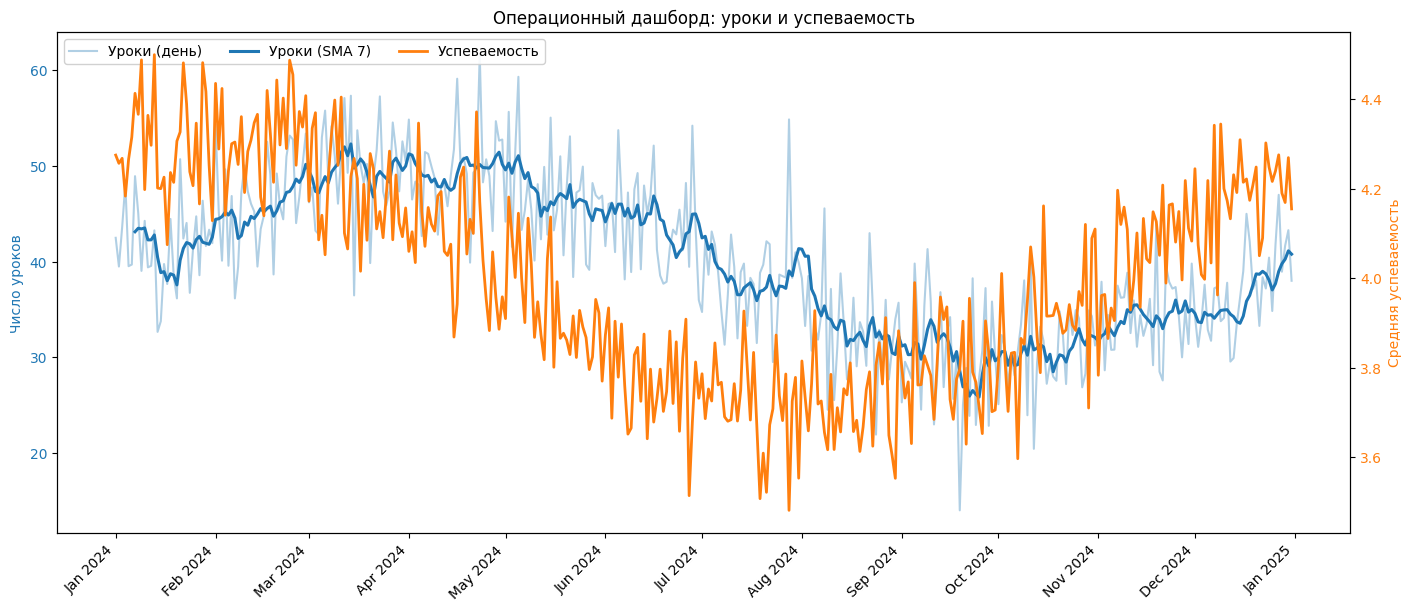

In [24]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

dates = pd.date_range("2024-01-01", "2024-12-31", freq="D")
np.random.seed(42)
n = len(dates)
df = pd.DataFrame({
    "date": dates,
    "lessons": 40 + 10 * np.sin(np.arange(n) * 2 * np.pi / 365) + np.random.randn(n) * 5,
    "avg_grade": 4.0 + 0.3 * np.sin(np.arange(n) * 2 * np.pi / 365 + 1) + np.random.randn(n) * 0.1,
})

fig, ax1 = plt.subplots(figsize=(14, 6), layout="constrained")

c1, c2 = "#1f77b4", "#ff7f0e"   # синий и оранжевый — различимы для дальтоников

# Дневные уроки — бледные, SMA(7) — плотная линия
ax1.plot(df["date"], df["lessons"], color=c1, alpha=0.35, label="Уроки (день)")
ax1.plot(df["date"], df["lessons"].rolling(7).mean(), color=c1, linewidth=2.2,
         label="Уроки (SMA 7)")
ax1.set_ylabel("Число уроков", color=c1)
ax1.tick_params(axis="y", labelcolor=c1)
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0f}"))

# Правая ось — успеваемость
ax2 = ax1.twinx()
ax2.plot(df["date"], df["avg_grade"], color=c2, linewidth=2, label="Успеваемость")
ax2.set_ylabel("Средняя успеваемость", color=c2)
ax2.tick_params(axis="y", labelcolor=c2)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.1f}"))

# Даты по месяцам
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax1.get_xticklabels(), rotation=45, ha="right")

# Общая легенда с обеих осей
l1, lab1 = ax1.get_legend_handles_labels()
l2, lab2 = ax2.get_legend_handles_labels()
ax1.legend(l1 + l2, lab1 + lab2, loc="upper left", ncol=3, framealpha=0.9)

ax1.set_title("Операционный дашборд: уроки и успеваемость")
plt.savefig("ops_dashboard_web.png", dpi=150, bbox_inches="tight")   # для веба
plt.savefig("ops_dashboard_print.png", dpi=300, bbox_inches="tight") # для печати
plt.show()

# Комментарии:
# - rolling(7) убирает дневной шум и подчёркивает недельный тренд.
# - Без twinx успеваемость 3.0–4.8 «схлопнется» на фоне 20–60 уроков.
# - Цвета осей = цвет данных → читатель мгновенно понимает, какая шкала чья.
# - FuncFormatter — самый простой путь для ad-hoc формата (без класса).

Уровень 5. Эксперт

Задача 43 (Slider с PlotState-датаклассом)

Школа проводит интерактивную демонстрацию для управления образования: покажите, как меняется прогноз успеваемости при разных темпах роста мотивации и сезонных коэффициентах. Интерактивные виджеты превращают статичный график в панель управления. Реализуйте @dataclass class PlotState: growth: float = 0.05; seasonality: float = 0.2 и два Slider — «темп роста» (0.01–0.20) и «сезонность» (0.0–1.0). В callback def update(_): state.growth = slider_growth.val; state.seasonality = slider_season.val; y = base * (1 + state.growth) ** months * (1 + state.seasonality * np.sin(2 * np.pi * months / 12)); line.set_ydata(y); fig.canvas.draw_idle(). Расположите слайдеры через fig.subplots_adjust(bottom=0.25) и fig.add_axes([0.15, 0.15, 0.7, 0.03]) (и второй на [0.15, 0.05, ...]). Ожидаемый вывод: слайдеры внизу, график перестраивается в реальном времени. В комментариях объясните: зачем PlotState (отделить состояние от вида — упрощает тестирование); почему обязательно fig.canvas.draw_idle() (без него данные обновятся, но график не перерисуется); что произойдёт без subplots_adjust (слайдеры перекроют график); как blitting ускоряет перерисовку (перерисовывается только линия, а не вся фигура); как valfmt="%.2f" форматирует отображение значения (0.05 → "0.05"); что будет при valstep=0.01 (значения квантуются — удобно для «шага 1%»).

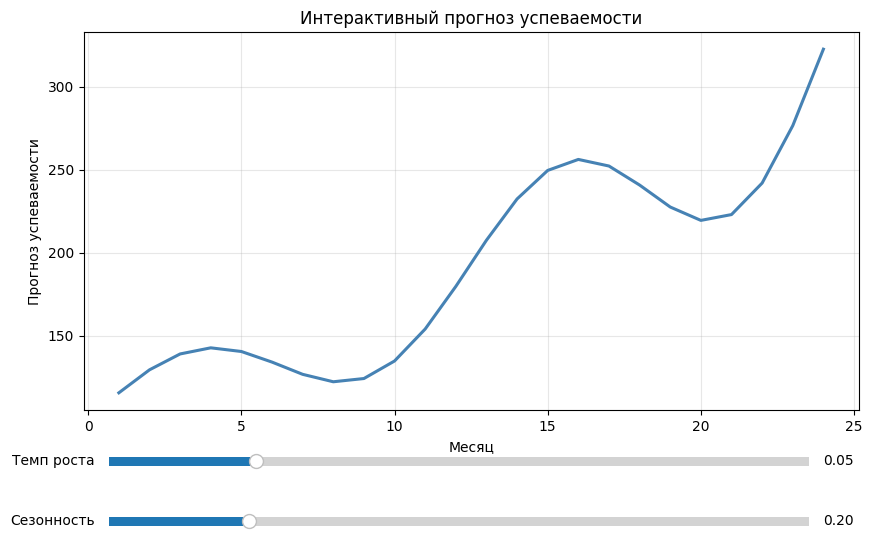

In [25]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib.widgets import Slider
from dataclasses import dataclass

# В Colab для интерактивности виджетов:
# from google.colab import output; output.enable_custom_widget_manager()

@dataclass
class PlotState:
    growth: float = 0.05
    seasonality: float = 0.2

state = PlotState()
months = np.arange(1, 25)
base = 100.0

fig, ax = plt.subplots(figsize=(10, 6))
# subplots_adjust освобождает место под слайдеры снизу (иначе они перекроют график)
fig.subplots_adjust(bottom=0.25)

y = base * (1 + state.growth) ** months * (1 + state.seasonality * np.sin(2 * np.pi * months / 12))
line, = ax.plot(months, y, color="steelblue", linewidth=2.2)
ax.set_xlabel("Месяц"); ax.set_ylabel("Прогноз успеваемости")
ax.set_title("Интерактивный прогноз успеваемости")
ax.grid(alpha=0.3)

# Слайдеры
ax_growth = fig.add_axes([0.15, 0.15, 0.70, 0.03])
ax_season = fig.add_axes([0.15, 0.05, 0.70, 0.03])

slider_growth = Slider(ax_growth, "Темп роста",
                       0.01, 0.20, valinit=state.growth,
                       valfmt="%.2f", valstep=0.01)  # шаг 1%
slider_season = Slider(ax_season, "Сезонность",
                       0.0, 1.0, valinit=state.seasonality,
                       valfmt="%.2f")

def update(_):
    state.growth = slider_growth.val
    state.seasonality = slider_season.val
    y_new = base * (1 + state.growth) ** months * (1 + state.seasonality * np.sin(2 * np.pi * months / 12))
    line.set_ydata(y_new)
    ax.set_ylim(y_new.min() * 0.9, y_new.max() * 1.1)
    # БЕЗ draw_idle данные обновятся, но фигура не перерисуется
    fig.canvas.draw_idle()

slider_growth.on_changed(update)
slider_season.on_changed(update)
plt.show()

# Комментарии:
# - PlotState отделяет СОСТОЯНИЕ (данные) от ВИДА (графика) — легче тестировать.
# - draw_idle — асинхронная перерисовка (быстрее draw()).
# - Blitting (опционально) перерисовывает только линию, а не всю фигуру.
# - valstep=0.01 квантует значения — удобно для «шага 1%».

Задача 44 (Button, RadioButtons, CheckButtons в одном дашборде)

Школа показывает управлению образования интерактивный дашборд с 4 виджетами: слайдер темпа роста, радио-кнопки для выбора параллели (5 / 9 / 11), чекбоксы для включения/отключения сетки и легенды, кнопка «Сброс». Реализуйте class InteractivePlot с методами _update, _change_parallel, _toggle_grid, _reset. Используйте RadioButtons.on_clicked(callback) (принимает метку выбранного варианта), CheckButtons.on_clicked(callback) (принимает метку кликнутого флажка), Button.on_clicked(callback) (принимает event, но обычно игнорируется). Ожидаемый вывод: 4 виджета работают совместно; кнопка сброса возвращает исходные значения. В комментариях объясните: чем RadioButtons отличается от CheckButtons (первый — один активный, второй — много независимых); как Button.on_clicked(callback) отличается от Slider.on_changed(callback) (первый по клику, второй при изменении); зачем хранить ссылки на виджеты (self.slider = Slider(...) — иначе GC удалит); как set_active(index) у RadioButtons программно выбирает вариант; почему activecolor улучшает UX (выделяет активный вариант); что произойдёт при двух активных RadioButtons (это не «галочки», нельзя выбрать два — попытка вызовет set_active и сбросит первый).

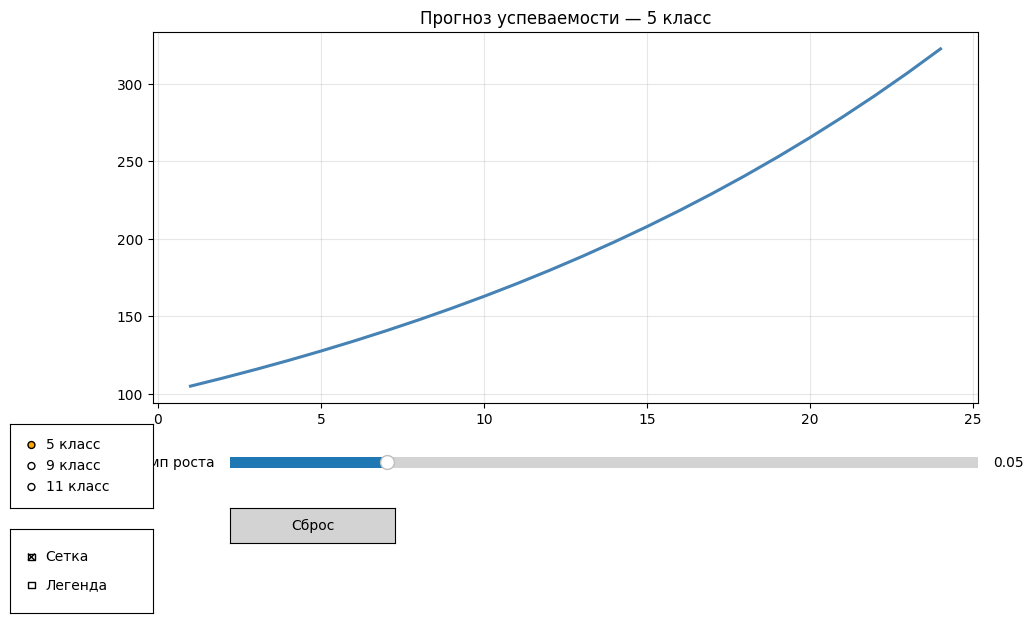

In [26]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib.widgets import Button, RadioButtons, CheckButtons, Slider

# Colab: from google.colab import output; output.enable_custom_widget_manager()

class InteractivePlot:
    def __init__(self):
        self.parallels = {"5 класс": 1.0, "9 класс": 1.3, "11 класс": 1.5}
        self.current = "5 класс"
        self.show_grid = True
        self.months = np.arange(1, 25)
        self.growth = 0.05
        self.base = 100.0 * self.parallels[self.current]

        self.fig, self.ax = plt.subplots(figsize=(11, 7))
        self.fig.subplots_adjust(bottom=0.35, left=0.15)

        y = self.base * (1 + self.growth) ** self.months
        self.line, = self.ax.plot(self.months, y, color="steelblue", linewidth=2.2)
        self.ax.set_title(f"Прогноз успеваемости — {self.current}")
        self.ax.grid(self.show_grid, alpha=0.3)

        # --- Виджеты ---
        ax_growth = self.fig.add_axes([0.22, 0.25, 0.68, 0.03])
        ax_radio  = self.fig.add_axes([0.02, 0.20, 0.13, 0.12])
        ax_check  = self.fig.add_axes([0.02, 0.05, 0.13, 0.12])
        ax_reset  = self.fig.add_axes([0.22, 0.15, 0.15, 0.05])

        # Ссылки self.* обязательны — иначе GC удалит виджеты
        self.slider = Slider(ax_growth, "Темп роста", 0.01, 0.20,
                             valinit=self.growth, valfmt="%.2f", valstep=0.01)
        self.radio = RadioButtons(ax_radio, list(self.parallels.keys()),
                                  active=0, activecolor="orange")
        self.check = CheckButtons(ax_check, ["Сетка", "Легенда"], [True, False])
        self.btn = Button(ax_reset, "Сброс", color="lightgray", hovercolor="lightblue")

        self.slider.on_changed(self._update)
        self.radio.on_clicked(self._change_parallel)
        self.check.on_clicked(self._toggle_grid)
        self.btn.on_clicked(self._reset)

    def _update(self, val):
        self.growth = val
        y = self.base * (1 + self.growth) ** self.months
        self.line.set_ydata(y)
        self.ax.set_ylim(y.min() * 0.9, y.max() * 1.1)
        self.fig.canvas.draw_idle()

    def _change_parallel(self, label):
        self.current = label
        self.base = 100.0 * self.parallels[label]
        y = self.base * (1 + self.growth) ** self.months
        self.line.set_ydata(y)
        self.ax.set_title(f"Прогноз успеваемости — {label}")
        self.ax.set_ylim(y.min() * 0.9, y.max() * 1.1)
        self.fig.canvas.draw_idle()

    def _toggle_grid(self, label):
        if label == "Сетка":
            self.show_grid = not self.show_grid
            self.ax.grid(self.show_grid, alpha=0.3)
        elif label == "Легенда":
            if self.ax.get_legend():
                self.ax.get_legend().remove()
            else:
                self.ax.legend(["Прогноз"], loc="upper left")
        self.fig.canvas.draw_idle()

    def _reset(self, _event):
        self.slider.set_val(0.05)                 # триггерит on_changed → _update
        self.radio.set_active(0)                   # программный выбор первой опции
        self._change_parallel("5 класс")
        self.fig.canvas.draw_idle()

ip = InteractivePlot()
plt.show()

# Комментарии:
# - RadioButtons — один активный, CheckButtons — много независимых.
# - Button.on_clicked(cb) — по клику; Slider.on_changed(cb) — при каждом изменении.
# - self.slider = ... удерживает ссылку — иначе виджет соберёт GC.
# - RadioButtons.set_active(i) — программный выбор.
# - activecolor="orange" визуально выделяет активную опцию.

Уровень 6. Гуру

Задача 53 (ReportBuilder — ООП-обёртка для дашбордов)

Школа готовит ежемесячный отчёт из 5–9 графиков. Код легко превращается в «лапшу» из axes[i, j].plot(...). Правильная архитектура отделяет «что рисовать» от «как размещать». Реализуйте @dataclass class ReportPage: title: str; plot_fn: Callable[[Axes], None] и class ReportBuilder с build() (создаёт фигуру и размещает страницы), save(path, dpi) (вызывает build + savefig + plt.close). Соберите 5 страниц: динамика посещаемости (line), топ предметов (bar), распределение оценок (hist), успеваемость по классам (box), heatmap классов по месяцам (imshow). Пустые ячейки скройте через axes.flat[n:].axis("off"). Ожидаемый вывод: одна фигура с 5 графиками. В комментариях объясните: зачем ReportPage (разделяет «что рисовать» и «как размещать» — легко добавить новый график); как axes.flat[n:] скрывает пустые ячейки при нечётном числе графиков; зачем plt.close(fig) (освободить память при генерации десятков отчётов); как расширить to_pdf через PdfPages (многостраничный отчёт); как связать с PlotConfig (передавать конфигурацию в __init__); когда такой класс — овер-инжиниринг (для одного графика проще plt.subplots).

In [27]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Callable
from matplotlib.axes import Axes

@dataclass
class ReportPage:
    title: str
    plot_fn: Callable[[Axes], None]

class ReportBuilder:
    def __init__(self, pages, ncols=3, figsize=(15, 10)):
        self.pages = pages
        self.ncols = ncols
        self.figsize = figsize
        self.fig = None

    def build(self):
        n = len(self.pages)
        nrows = (n + self.ncols - 1) // self.ncols
        self.fig, axes_arr = plt.subplots(nrows, self.ncols,
                                          figsize=self.figsize,
                                          layout="constrained")
        axes = np.atleast_1d(axes_arr).flatten()

        for ax, page in zip(axes, self.pages):
            page.plot_fn(ax)
            ax.set_title(page.title, fontweight="bold")

        # Скрыть пустые ячейки при нечётном числе страниц
        for ax in axes[n:]:
            ax.axis("off")

        return self.fig

    def save(self, path, dpi=150):
        fig = self.build()
        fig.savefig(path, dpi=dpi, bbox_inches="tight")
        plt.close(fig)      # освобождает память — критично при десятках отчётов
        return path

# --- Данные ---
np.random.seed(42)
df = pd.DataFrame({
    "date": pd.date_range("2024-01-01", periods=100),
    "students": 800 + np.random.randint(-50, 60, 100).cumsum() % 200,
    "grade": np.random.choice(["5","4","3","2"], 100, p=[.3,.4,.25,.05]),
    "class": np.random.choice(["9А","9Б","10А","10Б","11А"], 100),
    "subject": np.random.choice(["Матем","Рус","Физ","Хим","Ист"], 100),
    "month": np.random.choice(["Янв","Фев","Мар","Апр","Май"], 100),
})

def plot_line(ax):
    ax.plot(df["date"], df["students"], color="steelblue")
def plot_bar(ax):
    t = df["subject"].value_counts()
    ax.bar(t.index, t.values, color="seagreen")
def plot_hist(ax):
    ax.hist(df["students"], bins=15, color="orange", edgecolor="white")
def plot_box(ax):
    classes = sorted(df["class"].unique())
    groups = [df[df["class"] == c]["students"].values for c in classes]
    ax.boxplot(groups, tick_labels=classes, patch_artist=True)
def plot_heatmap(ax):
    pivot = pd.crosstab(df["class"], df["month"])
    im = ax.imshow(pivot.values, cmap="Blues", aspect="auto")
    ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)));  ax.set_yticklabels(pivot.index)

pages = [
    ReportPage("Динамика посещаемости", plot_line),
    ReportPage("Топ предметов", plot_bar),
    ReportPage("Распределение оценок", plot_hist),
    ReportPage("Успеваемость по классам", plot_box),
    ReportPage("Heatmap классов × месяцев", plot_heatmap),
]

builder = ReportBuilder(pages)
builder.save("report_builder.png", dpi=150)
print("Сохранено: report_builder.png")
plt.show()

# Комментарии:
# - ReportPage разделяет «что» и «как» — добавить страницу = новая запись.
# - axes.flat[n:] — плоский итератор по осям; пустые скрываем через axis("off").
# - plt.close(fig) — при 50+ графиках без закрытия будет MemoryError.
# - Расширить до PDF: with PdfPages("report.pdf") as pdf: pdf.savefig(fig).
# - PlotConfig из задачи 2 — передавать в __init__ вместо figsize по умолчанию.
# - Для 1 графика этот класс — овер-инжиниринг, для 5+ — норма.

Сохранено: report_builder.png


Задача 54 (LearningCurveAnalyzer — автоматическая диагностика)

Школа обучает модели прогноза успеваемости для 5 предметов и хочет автоматически получать диагноз «переобучение / недообучение / хорошо». Кривые обучения мощны, но интерпретировать их вручную утомительно. Реализуйте class LearningCurveAnalyzer с методами fit() (вызывает learning_curve и сохраняет train_mean, val_mean, train_std, val_std), diagnose() -> str (пороги: gap = train_mean[-1] - val_mean[-1] > 0.1 → overfitting; val_mean[-1] < 0.7 → underfitting; иначе good), plot(ax=None) (рисует с fill_between), compare(others: list) (сравнивает несколько моделей на одной фигуре). Обучите три модели, сравните, постройте три learning curves с диагнозами в заголовках. Ожидаемый вывод: 3 графика с диагнозами. В комментариях объясните: зачем diagnose (автоматизация — не нужно каждый раз смотреть на график); как пороги gap > 0.1 и val_mean < 0.7 определяют диагноз (эмпирические — зависят от задачи); зачем fit() возвращает self (fluent API — LearningCurveAnalyzer(...).fit().plot()); как логировать результаты в pd.DataFrame для отчёта (pd.DataFrame({"model": ..., "diagnosis": ..., "val_mean": ...})); как связать с ML-дашбордом (задача 56) — learning curves как дополнение к метрикам; когда compare полезнее одиночного plot (сравнение моделей одной серии).

                 model  max_depth    diagnosis  val_acc_last
DecisionTreeClassifier        3.0 Недообучение         0.687
DecisionTreeClassifier       20.0 Переобучение         0.812
RandomForestClassifier        NaN       Хорошо         0.944


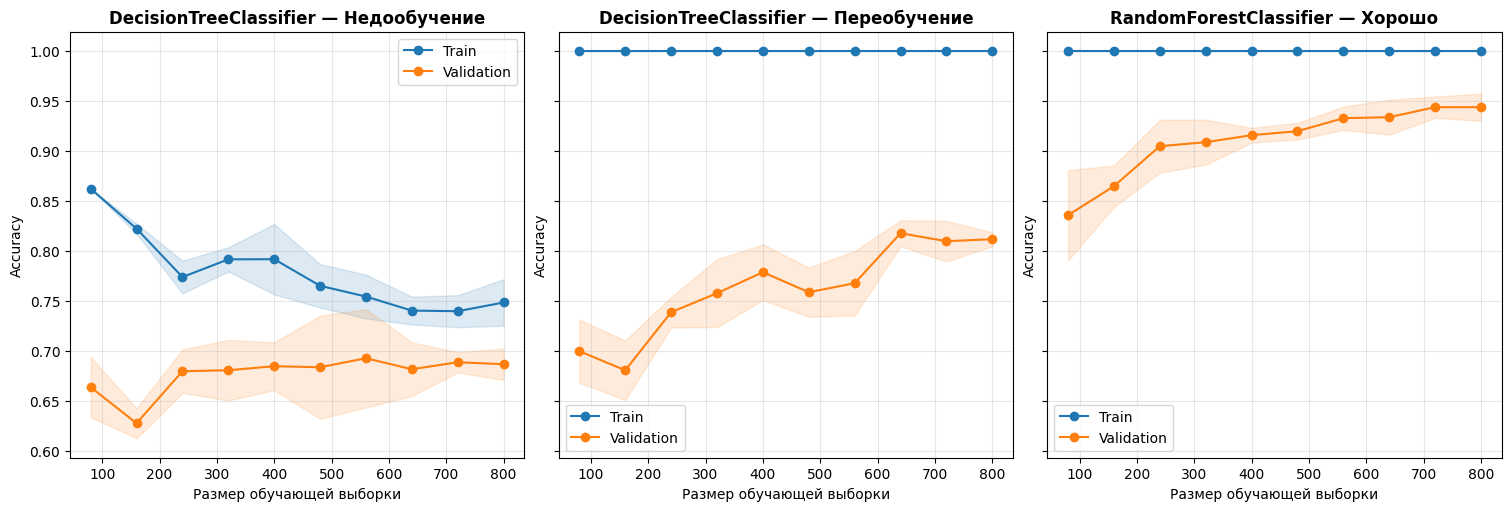

In [28]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification

class LearningCurveAnalyzer:
    def __init__(self, model, X, y, cv=5):
        self.model, self.X, self.y, self.cv = model, X, y, cv
        self.sizes = self.train_mean = self.val_mean = None
        self.train_std = self.val_std = None

    def fit(self):
        self.sizes, tr, val = learning_curve(
            self.model, self.X, self.y,
            train_sizes=np.linspace(0.1, 1.0, 10),
            cv=self.cv, scoring="accuracy", n_jobs=-1,
        )
        self.train_mean, self.train_std = tr.mean(axis=1), tr.std(axis=1)
        self.val_mean,   self.val_std   = val.mean(axis=1), val.std(axis=1)
        return self   # fluent API: LearningCurveAnalyzer(...).fit().plot()

    def diagnose(self) -> str:
        gap = self.train_mean[-1] - self.val_mean[-1]
        if gap > 0.10:                  return "Переобучение"
        if self.val_mean[-1] < 0.70:    return "Недообучение"
        return "Хорошо"

    def plot(self, ax=None):
        if ax is None:
            _, ax = plt.subplots(figsize=(8, 6))
        ax.fill_between(self.sizes, self.train_mean - self.train_std,
                        self.train_mean + self.train_std, alpha=0.15, color="C0")
        ax.fill_between(self.sizes, self.val_mean - self.val_std,
                        self.val_mean + self.val_std, alpha=0.15, color="C1")
        ax.plot(self.sizes, self.train_mean, "o-", color="C0", label="Train")
        ax.plot(self.sizes, self.val_mean, "o-", color="C1", label="Validation")
        ax.set_xlabel("Размер обучающей выборки")
        ax.set_ylabel("Accuracy")
        ax.set_title(f"{type(self.model).__name__} — {self.diagnose()}",
                     fontweight="bold")
        ax.legend(); ax.grid(alpha=0.3)
        return ax

    @staticmethod
    def compare(analyzers, figsize=(15, 5)):
        fig, axes = plt.subplots(1, len(analyzers), figsize=figsize,
                                 layout="constrained", sharey=True)
        for ax, a in zip(axes, analyzers):
            a.plot(ax)
        return fig

# --- Данные ---
X, y = make_classification(n_samples=1000, n_features=15, n_informative=10,
                           n_classes=3, n_clusters_per_class=1, random_state=42)

m1 = LearningCurveAnalyzer(DecisionTreeClassifier(max_depth=3,  random_state=42), X, y).fit()
m2 = LearningCurveAnalyzer(DecisionTreeClassifier(max_depth=20, random_state=42), X, y).fit()
m3 = LearningCurveAnalyzer(RandomForestClassifier(n_estimators=60, random_state=42), X, y).fit()

# Табличка для отчёта
summary = pd.DataFrame([
    {"model": type(m.model).__name__,
     "max_depth": getattr(m.model, "max_depth", "n/a"),
     "diagnosis": m.diagnose(),
     "val_acc_last": round(m.val_mean[-1], 3)}
    for m in (m1, m2, m3)
])
print(summary.to_string(index=False))

fig = LearningCurveAnalyzer.compare([m1, m2, m3])
plt.savefig("learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Комментарии:
# - diagnose() автоматизирует интерпретацию: не надо каждый раз смотреть в график.
# - Пороги gap>0.1 и val_mean<0.7 — эмпирические; в вашей задаче могут отличаться.
# - fit() возвращает self — позволяет цепочку ...fit().plot().
# - pd.DataFrame(...) — готовый отчёт для выгрузки в Excel/PDF.
# - compare() полезнее plot() когда сравниваем 3+ модели одной серии.
# - В ML-дашборде (задача 56) эти графики дополняют confusion/ROC/PR.

In [29]:
!ls -lh /content/*.png

-rw-r--r-- 1 root root  84K Nov 24 15:17 /content/annotations.png
-rw-r--r-- 1 root root 178K Nov 24 15:17 /content/attendance_config.png
-rw-r--r-- 1 root root  62K Nov 24 15:17 /content/attendance.png
-rw-r--r-- 1 root root 362K Nov 24 15:17 /content/dashboard.png
-rw-r--r-- 1 root root 502K Nov 24 15:17 /content/date_formats.png
-rw-r--r-- 1 root root 141K Nov 24 15:17 /content/gridspec.png
-rw-r--r-- 1 root root 141K Nov 24 15:17 /content/learning_curves.png
-rw-r--r-- 1 root root 141K Nov 24 15:17 /content/mosaic.png
-rw-r--r-- 1 root root 868K Nov 24 15:17 /content/ops_dashboard_print.png
-rw-r--r-- 1 root root 358K Nov 24 15:17 /content/ops_dashboard_web.png
-rw-r--r-- 1 root root 182K Nov 24 15:17 /content/report_builder.png
-rw-r--r-- 1 root root 298K Nov 24 15:17 /content/two_legends.png
